In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import eclipsr as ecl

import time
from pathlib import Path
from astropy.io import fits

import lightkurve as lk

In [ ]:
## The object is tic_373777814, having 5 fits files in total.

PATH_LC = Path('..') / 'lightcurves'
TIC = '52281550'  

In [3]:
folder = PATH_LC / ('tic_' + TIC)
files = sorted(folder.rglob('*.fits'))

print(f'{len(files)} files found\n')
for f in files:
    print(' ', f.relative_to(folder))

3 files found

  mastDownload/TESS/tess2025154050500-s0093-0000000382067804-0290-s/tess2025154050500-s0093-0000000382067804-0290-s_lc.fits
  mastDownload/TESS/tess2025180145000-s0094-0000000382067804-0291-s/tess2025180145000-s0094-0000000382067804-0291-s_lc.fits
  mastDownload/TESS/tess2025206162959-s0095-0000000382067804-0292-s/tess2025206162959-s0095-0000000382067804-0292-s_lc.fits


In [4]:
for f in files:
    with fits.open(f) as hdul:
        h0 = hdul[0].header
        print(f.name)
        print('   HLSPID  :', h0.get('HLSPID'))
        print('   ORIGIN  :', h0.get('ORIGIN'))
        print('   CREATOR :', h0.get('CREATOR'))
        print('   SECTOR  :', h0.get('SECTOR'))
        print('   TELESCOP:', h0.get('TELESCOP'))
        print('   columns :', hdul[1].columns.names)
        print()

tess2025154050500-s0093-0000000382067804-0290-s_lc.fits
   HLSPID  : None
   ORIGIN  : NASA/Ames
   CREATOR : 105289 LightCurveExporterPipelineModule
   SECTOR  : 93
   TELESCOP: TESS
   columns : ['TIME', 'TIMECORR', 'CADENCENO', 'SAP_FLUX', 'SAP_FLUX_ERR', 'SAP_BKG', 'SAP_BKG_ERR', 'PDCSAP_FLUX', 'PDCSAP_FLUX_ERR', 'QUALITY', 'PSF_CENTR1', 'PSF_CENTR1_ERR', 'PSF_CENTR2', 'PSF_CENTR2_ERR', 'MOM_CENTR1', 'MOM_CENTR1_ERR', 'MOM_CENTR2', 'MOM_CENTR2_ERR', 'POS_CORR1', 'POS_CORR2']

tess2025180145000-s0094-0000000382067804-0291-s_lc.fits
   HLSPID  : None
   ORIGIN  : NASA/Ames
   CREATOR : 105889 LightCurveExporterPipelineModule
   SECTOR  : 94
   TELESCOP: TESS
   columns : ['TIME', 'TIMECORR', 'CADENCENO', 'SAP_FLUX', 'SAP_FLUX_ERR', 'SAP_BKG', 'SAP_BKG_ERR', 'PDCSAP_FLUX', 'PDCSAP_FLUX_ERR', 'QUALITY', 'PSF_CENTR1', 'PSF_CENTR1_ERR', 'PSF_CENTR2', 'PSF_CENTR2_ERR', 'MOM_CENTR1', 'MOM_CENTR1_ERR', 'MOM_CENTR2', 'MOM_CENTR2_ERR', 'POS_CORR1', 'POS_CORR2']

tess2025206162959-s0095-000000

In [ ]:
FLUX_CANDIDATES = ['KSPSAP_FLUX', 'DET_FLUX',
                   'cal_aper_flux', 'cal_psf_flux', 'SAP_FLUX', 'FLUX']

def read_lc(path):
    """tek fits -> (time, normalize edilmis flux, pipeline, sector)"""
    with fits.open(path) as hdul:
        h0, d = hdul[0].header, hdul[1].data
        cols = hdul[1].columns.names

        fcol = next((c for c in FLUX_CANDIDATES if c in cols), None)
        if fcol is None:
            raise ValueError(f'flux kolonu bulunamadi: {cols}')

        t = np.asarray(d['TIME'], dtype=float)
        y = np.asarray(d[fcol], dtype=float)
        q = np.asarray(d['QUALITY']) if 'QUALITY' in cols else np.zeros_like(t)

        good = np.isfinite(t) & np.isfinite(y) & (y > 0) & (q == 0)
        t, y = t[good], y[good]
        y = y / np.median(y) # sektor bazinda normalize

        pipe = (h0.get('HLSPID') or 'SPOC').upper()
        sector = h0.get('SECTOR')
    return t, y, pipe, sector, fcol

lcs = [read_lc(f) for f in files]
for (t, y, pipe, sec, fcol), f in zip(lcs, files):
    print(f'{pipe:12s} s{sec:<4} {len(t):6d} nokta  cad~{np.median(np.diff(t))*24*60:5.1f} dk  [{fcol}]')

SPOC         s93    14800 nokta  cad~  2.0 dk  [SAP_FLUX]
SPOC         s94    14790 nokta  cad~  2.0 dk  [SAP_FLUX]
SPOC         s95    14949 nokta  cad~  2.0 dk  [SAP_FLUX]


In [8]:
from collections import Counter

print(Counter(pipe for _, _, pipe, _, _ in lcs))

PRIORITY = ['SPOC', 'QLP', 'TGLC', 'T16']
available = {pipe for _, _, pipe, _, _ in lcs}
chosen = next((p for p in PRIORITY if p in available), sorted(available)[0])

sel = [l for l in lcs if l[2] == chosen]
print(f'\nsecilen pipeline: {chosen}  ({len(sel)} sektor)')

Counter({'SPOC': 3})

secilen pipeline: SPOC  (3 sektor)


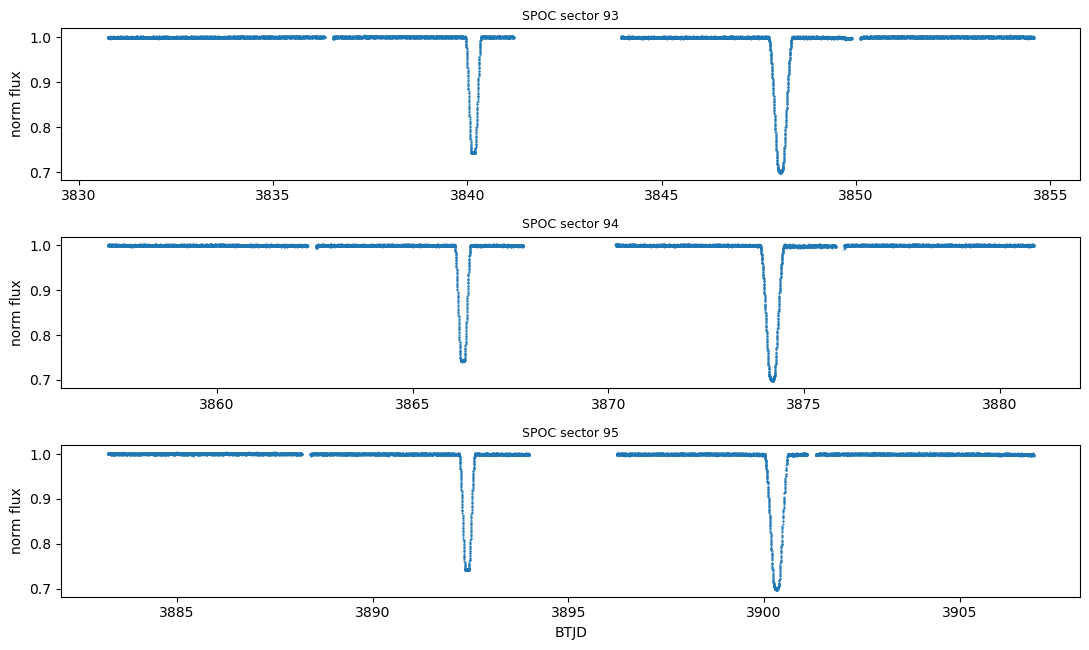

In [9]:
fig, axes = plt.subplots(len(sel), 1, figsize=(11, 2.2 * len(sel)), squeeze=False)
for ax, (t, y, pipe, sec, _) in zip(axes[:, 0], sel):
    ax.plot(t, y, '.', ms=1)
    ax.set_title(f'{pipe} sector {sec}', fontsize=9)
    ax.set_ylabel('norm flux')
axes[-1, 0].set_xlabel('BTJD')
plt.tight_layout()

44539 nokta, baseline 76.1 gun
1 gunden buyuk 5 bosluk, en buyugu 2.8 gun


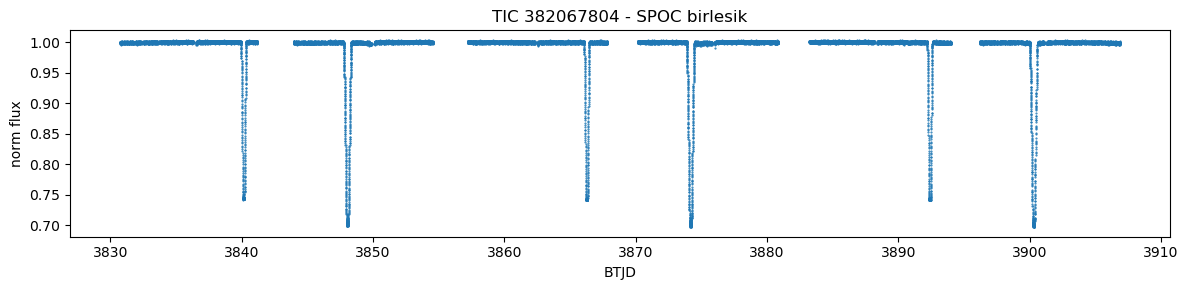

In [10]:
times = np.concatenate([l[0] for l in sel])
signal = np.concatenate([l[1] for l in sel])

order = np.argsort(times)             # rglob alfabetik verir, kronolojik degil
times, signal = times[order], signal[order]

print(f'{len(times)} nokta, baseline {times[-1] - times[0]:.1f} gun')

gaps = np.diff(times)
big = np.where(gaps > 1.0)[0]
print(f'1 gunden buyuk {len(big)} bosluk, en buyugu {gaps.max():.1f} gun')

plt.figure(figsize=(12, 3))
plt.plot(times, signal, '.', ms=1)
plt.xlabel('BTJD'); plt.ylabel('norm flux'); plt.title(f'TIC {TIC} - {chosen} birlesik')
plt.tight_layout()

In [11]:
t_in, s_in = ecl.utility.ingest_signal(times, signal, tess_sectors=True)
print(f'ingest sonrasi: {len(times)} -> {len(t_in)} nokta')

res_multi = ecl.find_eclipses(t_in, s_in, mode=2, tess_sectors=True)

ingest sonrasi: 44539 -> 44539 nokta


In [12]:
for t, y, pipe, sec, _ in sel:
    ti, si = ecl.utility.ingest_signal(t, y, tess_sectors=True)
    r = ecl.find_eclipses(ti, si, mode=2, tess_sectors=True)
    #print(f'sector {sec}: {r}')

#print(f'\nBIRLESIK : {res_multi}')

In [13]:
t_0, period, score, sine_like, wide, n_kernel, width_stats, depth_stats = \
    ecl.find_eclipses(t_in, s_in, mode=1, tess_sectors=True)

print('period   :', period)
print('t_0      :', t_0)
print('score    :', score)
print('sine_like:', sine_like)
print('wide     :', wide)
print('n_kernel :', n_kernel)
print('width_stats', np.shape(width_stats), '\n', width_stats)
print('depth_stats', np.shape(depth_stats), '\n', depth_stats)

period   : 13.065514824434729
t_0      : 3840.148416427759
score    : 0.9284350444595024
sine_like: False
wide     : False
n_kernel : [66 65 67]
width_stats (2, 2) 
 [[0.36944921 0.00226885]
 [0.4972312  0.04820506]]
depth_stats (2, 2) 
 [[0.2288054  0.00227406]
 [0.2389907  0.02434826]]


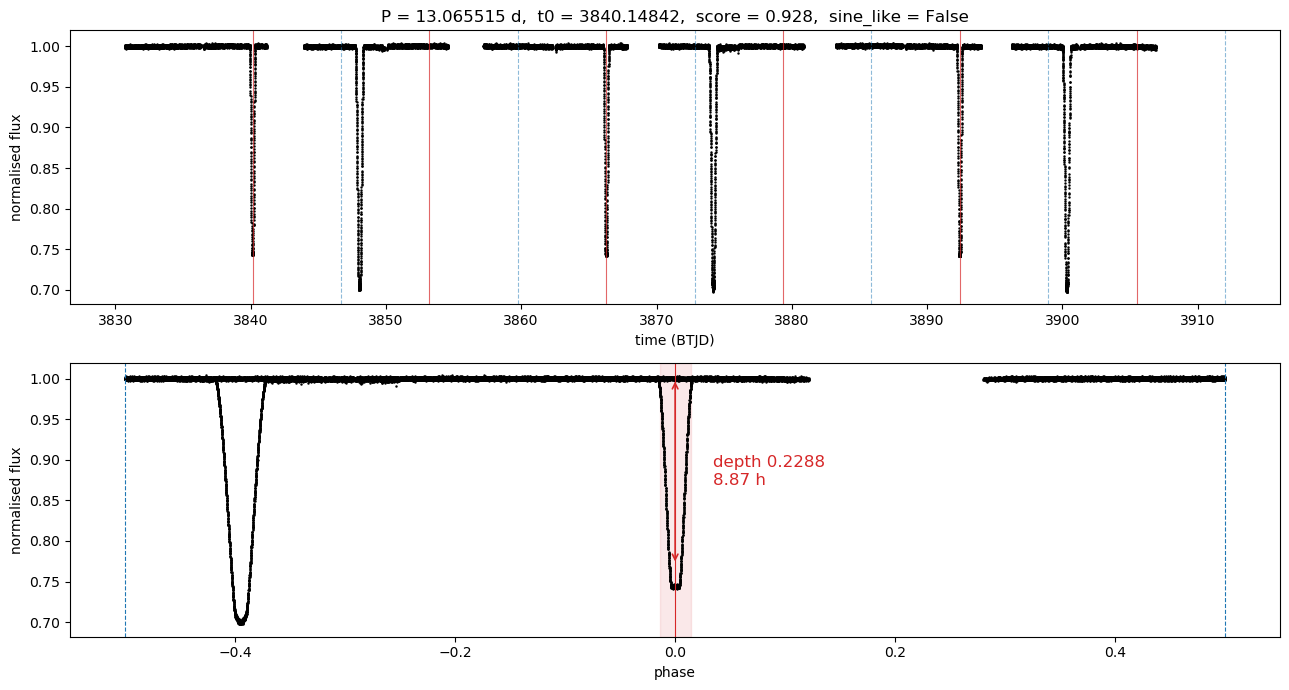

In [14]:
times_p, flux_p = t_in, s_in       # eclipsr'in gercekte gordugu diziler

dur_pri   = width_stats[0, 0]
depth_pri = depth_stats[0, 0]

fig, ax = plt.subplots(2, 1, figsize=(13, 7))

# --- 1. zaman serisi ---
ax[0].plot(times_p, flux_p, '.', ms=1.5, color='k')

n0 = int(np.floor((times_p.min() - t_0) / period))
n1 = int(np.ceil((times_p.max() - t_0) / period))
if n1 - n0 <= 400:                 # uzun baseline + kisa period = cizgi seli
    for n in range(n0, n1 + 1):
        tp = t_0 + n * period
        if times_p.min() <= tp <= times_p.max():
            ax[0].axvline(tp, color='tab:red', lw=0.8, alpha=0.7)
            ax[0].axvline(tp + period / 2, color='tab:blue', lw=0.8,
                          alpha=0.5, ls='--')
else:
    print(f'{n1 - n0} cevrim -> zaman serisine cizgi cizilmedi')

ax[0].set_xlabel('time (BTJD)')
ax[0].set_ylabel('normalised flux')
ax[0].set_title(f'P = {period:.6f} d,  t0 = {t_0:.5f},  '
                f'score = {score:.3f},  sine_like = {sine_like}')

# --- 2. katlanmis egri, birincil derinlik ve sure ---
phase = ((times_p - t_0) / period + 0.5) % 1 - 0.5
o = np.argsort(phase)
ax[1].plot(phase[o], flux_p[o], '.', ms=1.5, color='k')
ax[1].axvline(0, color='tab:red', lw=0.8)
ax[1].axvline(0.5, color='tab:blue', lw=0.8, ls='--')
ax[1].axvline(-0.5, color='tab:blue', lw=0.8, ls='--')

base   = np.median(flux_p)
dur_ph = dur_pri / period
ax[1].axvspan(-dur_ph / 2, dur_ph / 2, color='tab:red', alpha=0.10)

y_bot = base - depth_pri           # depth kesirli ise: base * (1 - depth_pri)
ax[1].annotate('', xy=(0, y_bot), xytext=(0, base),
               arrowprops=dict(arrowstyle='<->', color='tab:red', lw=1.2))
ax[1].text(dur_ph / 2 + 0.02, (base + y_bot) / 2,
           f'depth {depth_pri:.4f}\n{dur_pri * 24:.2f} h',
           color='tab:red', va='center', fontsize=12)

ax[1].set_xlabel('phase')
ax[1].set_ylabel('normalised flux')

plt.tight_layout(); plt.show()